In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import joblib

from sklearn.model_selection import train_test_split , RepeatedStratifiedKFold , cross_validate , cross_val_score , GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler , FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.metrics import classification_report , ConfusionMatrixDisplay , RocCurveDisplay , roc_auc_score
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv(r"archive\heart_failure_clinical_records_dataset.csv")

In [3]:
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [4]:
df.tail()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
294,62.0,0,61,1,38,1,155000.0,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.0,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.0,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.0,1.4,140,1,1,280,0
298,50.0,0,196,0,45,0,395000.0,1.6,136,1,1,285,0


In [5]:
df.shape

(299, 13)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [7]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


In [8]:
df.columns

Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='object')

### **Data Cleaning**

In [9]:
df.isnull().sum()

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.rename(columns= {'DEATH_EVENT': 'death_event'} , inplace= True)
df.columns

Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'death_event'],
      dtype='object')

In [12]:
binary_features = ['anaemia' , 'diabetes' , 'high_blood_pressure' , 'sex' , 'smoking']

df[binary_features + ['death_event']].isin([0 , 1]).all().all()

np.True_

In [13]:
cont_cols = ['age' , 'creatinine_phosphokinase' , 'ejection_fraction' , 'platelets' , 'serum_creatinine' , 'serum_sodium' , 'time']

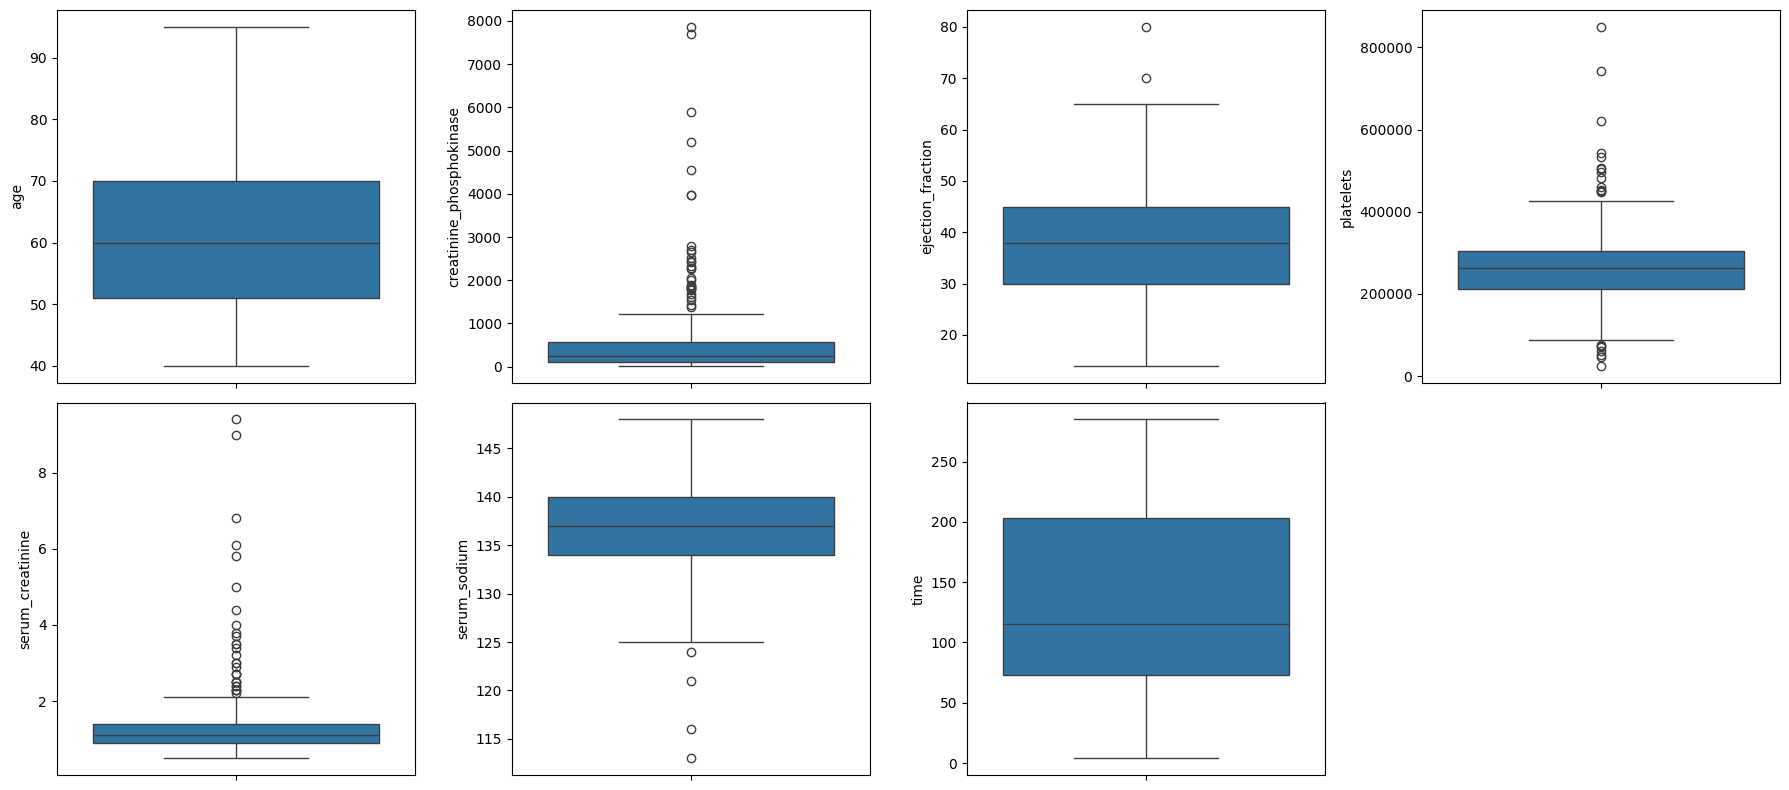

In [14]:
plt.figure(figsize= (18, 8))
for i, col in enumerate(cont_cols):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(y= df[col])
plt.tight_layout()
plt.show()

In [15]:
for col in cont_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)].shape[0]
    if outliers > 0:
        print(col , outliers)

creatinine_phosphokinase 29
ejection_fraction 2
platelets 21
serum_creatinine 29
serum_sodium 4


### **EDA && Visualization**

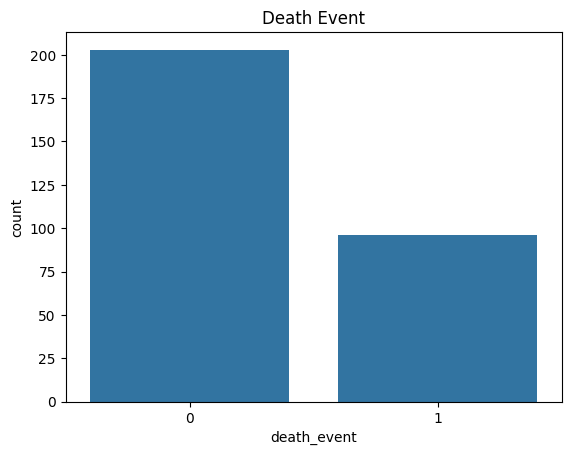

In [16]:
sns.countplot( x = 'death_event' , data= df)
plt.title('Death Event')
plt.show()

In [17]:
df['death_event'].value_counts()

death_event
0    203
1     96
Name: count, dtype: int64

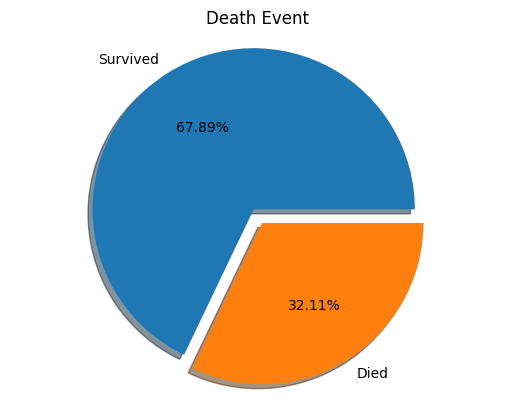

In [18]:
plt.pie(df['death_event'].value_counts() , 
        labels = ('Survived','Died') , 
        autopct = '%1.2f%%' , 
        shadow = True , 
        explode = [0 , 0.1])
plt.title('Death Event')
plt.axis('equal')
plt.show()

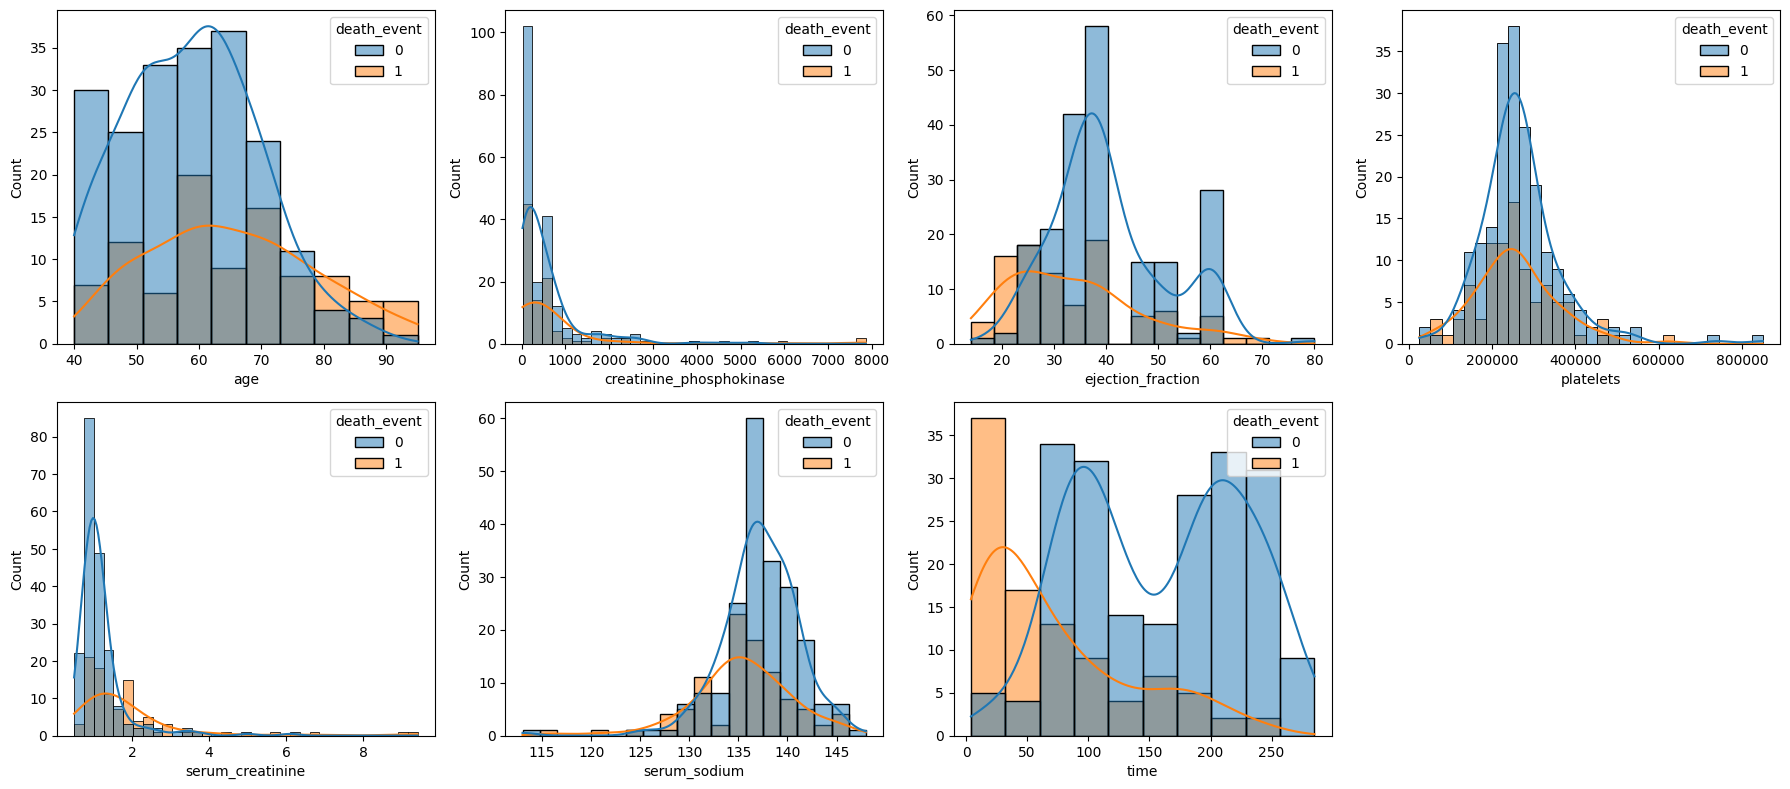

In [19]:
plt.figure(figsize= (18, 8))
for i, col in enumerate(cont_cols):
    plt.subplot(2, 4, i + 1)
    sns.histplot(data= df , x= col , hue= 'death_event' , kde= True)
plt.tight_layout()
plt.show()

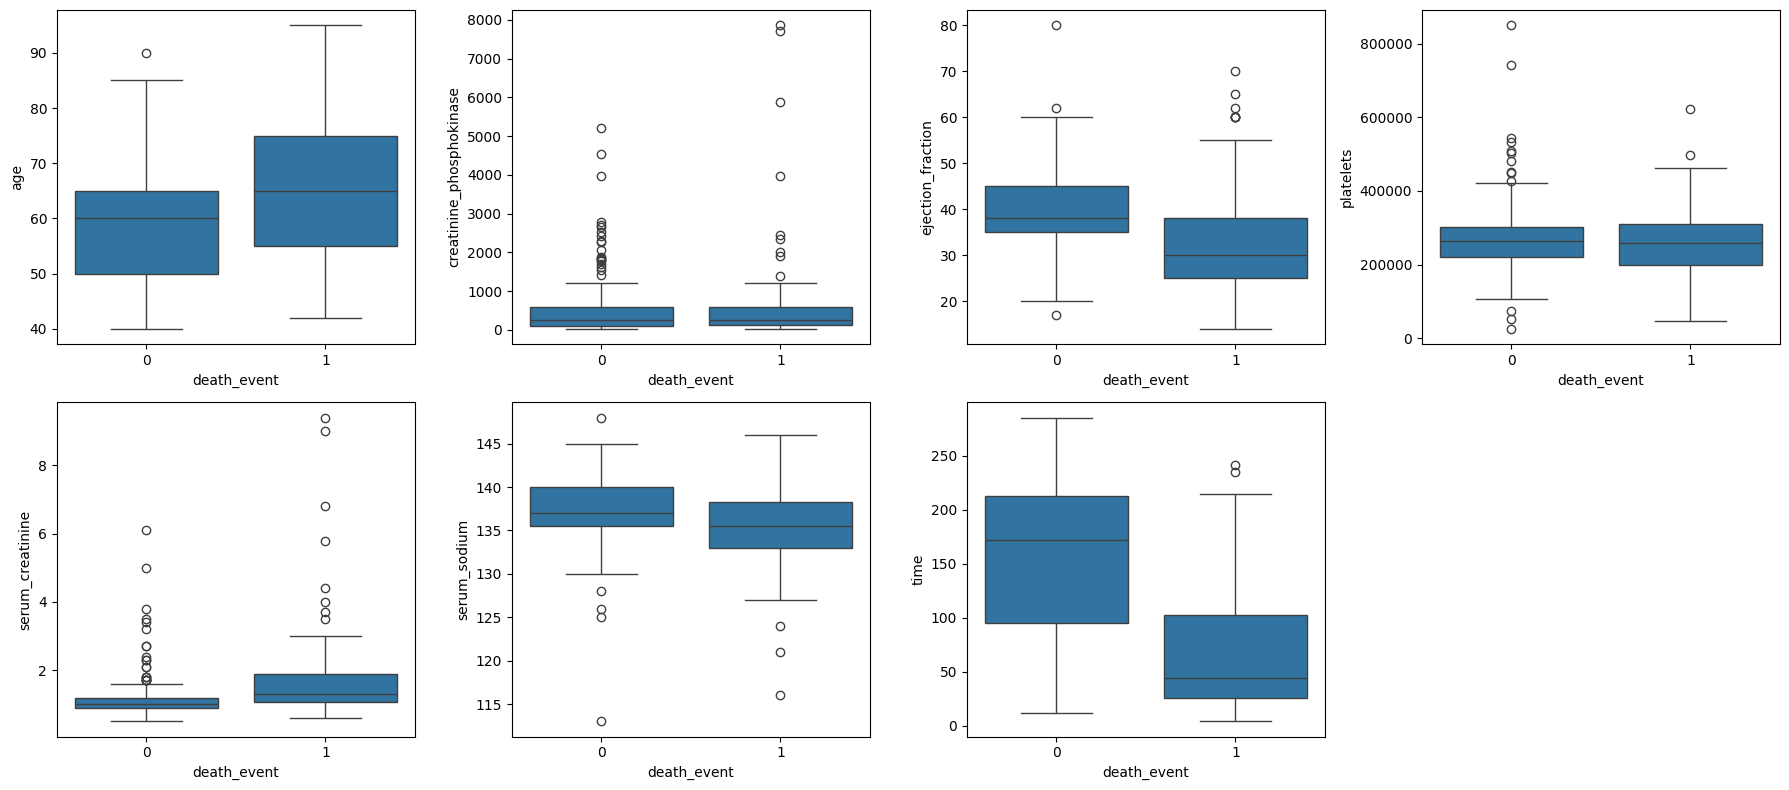

In [20]:
plt.figure(figsize= (18, 8))
for i, col in enumerate(cont_cols):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(x= 'death_event' , y= col , data= df)
plt.tight_layout()
plt.show()

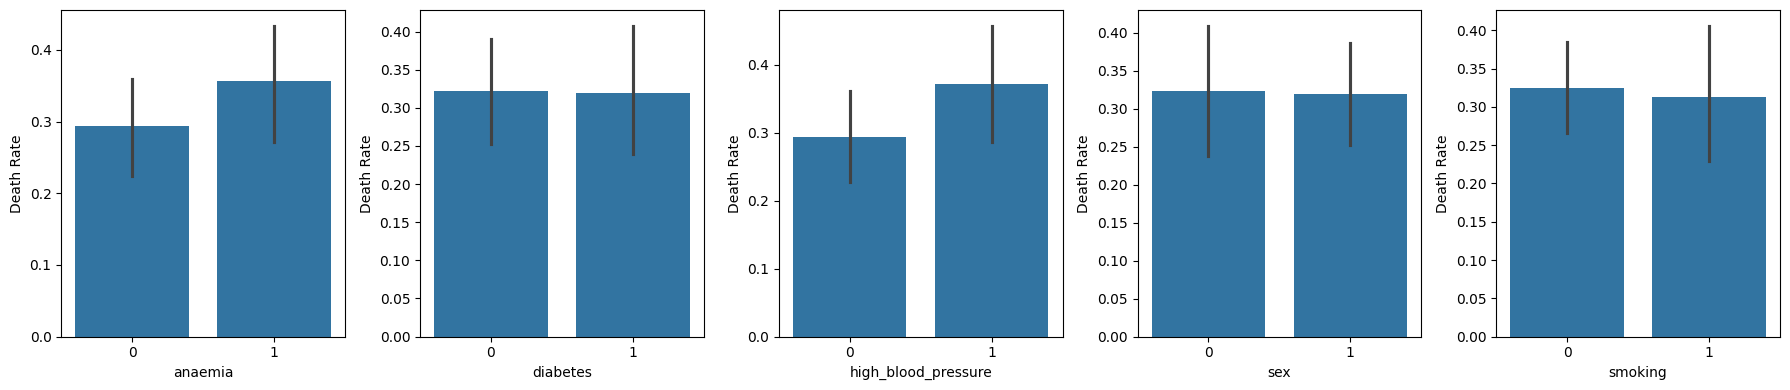

In [21]:
plt.figure(figsize= (18, 4))
for i, col in enumerate(binary_features):
    plt.subplot(1, 5, i + 1)
    sns.barplot(x= col , y= 'death_event' , data= df)
    plt.ylabel('Death Rate')
plt.tight_layout()
plt.show()

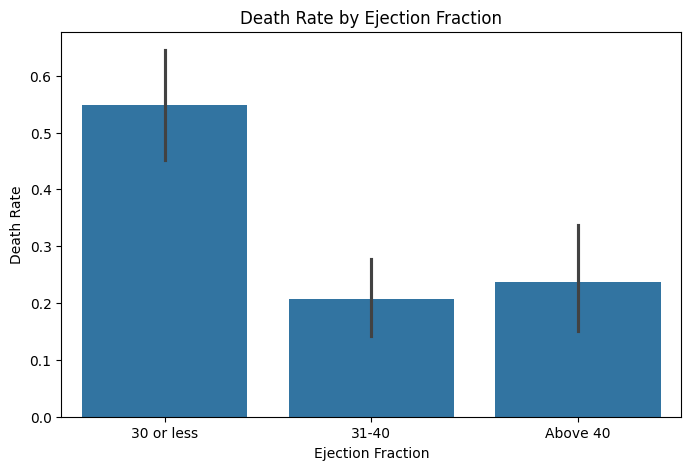

In [22]:
plt.figure(figsize= (8,5))
plt.title('Death Rate by Ejection Fraction')
sns.barplot( x = pd.cut(df['ejection_fraction'] , bins= [0 , 30 , 40 , 80] , labels= ['30 or less' , '31-40' , 'Above 40']) , y= df['death_event'])
plt.xlabel('Ejection Fraction')
plt.ylabel('Death Rate')
plt.show()

In [23]:
df[cont_cols].skew().sort_values(ascending= False)

creatinine_phosphokinase    4.463110
serum_creatinine            4.455996
platelets                   1.462321
ejection_fraction           0.555383
age                         0.423062
time                        0.127803
serum_sodium               -1.048136
dtype: float64

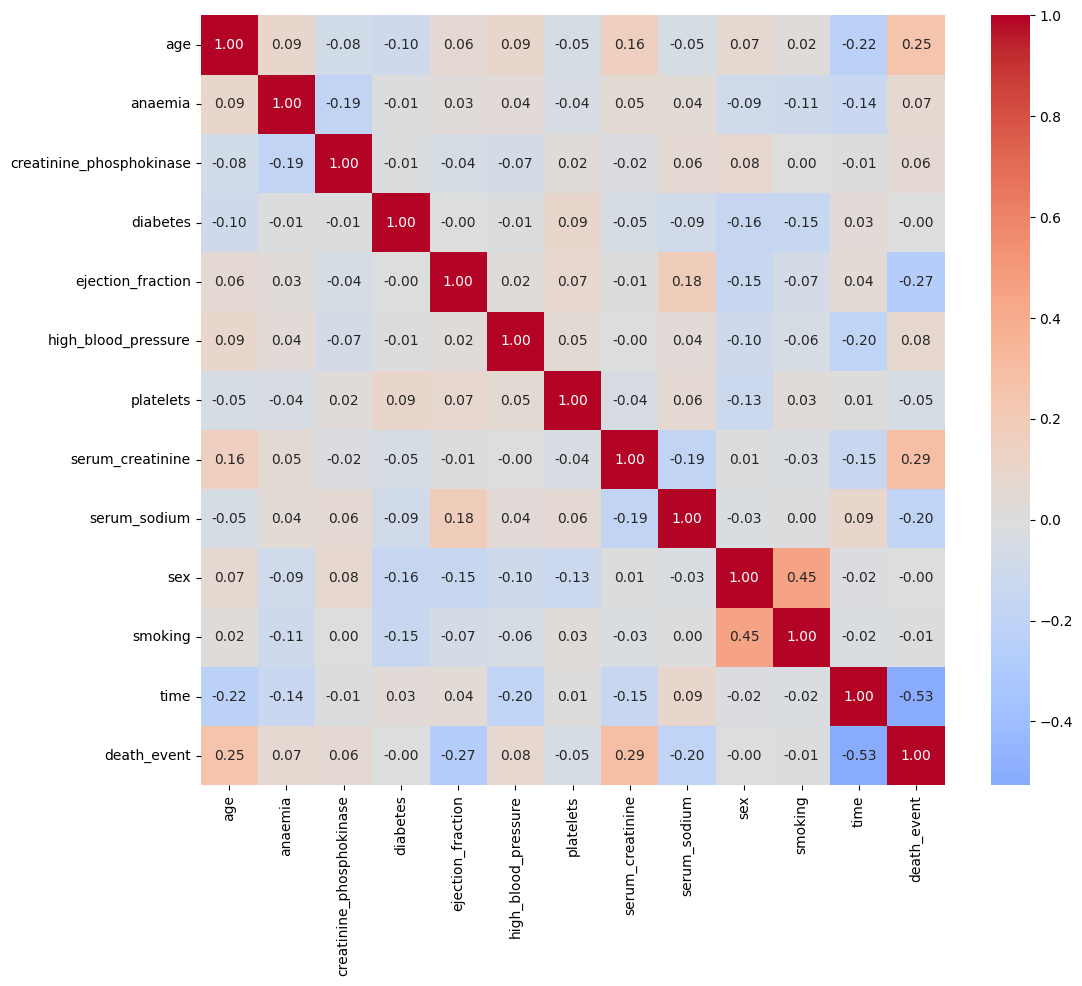

In [24]:
plt.figure(figsize= (12,10))
sns.heatmap (df.corr() , annot= True , fmt= '.2f' , cmap= 'coolwarm' , center= 0)
plt.show()

In [25]:
df.corr()['death_event'].drop('death_event').sort_values()

time                       -0.526964
ejection_fraction          -0.268603
serum_sodium               -0.195204
platelets                  -0.049139
smoking                    -0.012623
sex                        -0.004316
diabetes                   -0.001943
creatinine_phosphokinase    0.062728
anaemia                     0.066270
high_blood_pressure         0.079351
age                         0.253729
serum_creatinine            0.294278
Name: death_event, dtype: float64

In [26]:
df.groupby('death_event')['time'].describe()

,count,mean,std,min,25%,50%,75%,max
death_event,,,,,,,,
0,203.0,158.339901,67.742872,12.0,95.0,172.0,213.00,285.0
1,96.0,70.885417,62.378281,4.0,25.5,44.5,102.25,241.0


In [27]:
df[df['time'] < 30]['death_event'].value_counts()

death_event
1    31
0     4
Name: count, dtype: int64

In [28]:
X = df.drop(columns= ['death_event' , 'time'])
y = df['death_event']

In [29]:
skewed_cols = ['creatinine_phosphokinase' , 'serum_creatinine' , 'platelets']
num_cols = ['age' , 'ejection_fraction' , 'serum_sodium']

In [30]:
def build_preprocessor(num_cols):
    return ColumnTransformer([
        ('skewed' , Pipeline([('log' , FunctionTransformer(np.log1p)) , ('scale' , StandardScaler())]) , skewed_cols) ,
        ('num' , StandardScaler() , num_cols) ,
        ('binary' , 'passthrough' , binary_features)
    ])

preprocessor = build_preprocessor(num_cols)

### **Train Test Split**

In [31]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size= 0.2 , random_state= 42 , stratify= y)

In [32]:
X_train.shape , X_test.shape

((239, 11), (60, 11))

In [33]:
y_train.mean() , y_test.mean()

(np.float64(0.32217573221757323), np.float64(0.31666666666666665))

### **Model Training**

In [34]:
models = {
    'Logistic Regression': LogisticRegression(max_iter= 1000 , class_weight= 'balanced') ,
    'KNN': KNeighborsClassifier() ,
    'SVM': SVC(class_weight= 'balanced' , probability= True , random_state= 42) ,
    'Random Forest': RandomForestClassifier(class_weight= 'balanced' , random_state= 42) ,
    'Gradient Boosting': GradientBoostingClassifier(random_state= 42)
}

cv = RepeatedStratifiedKFold(n_splits= 5 , n_repeats= 3 , random_state= 42)

In [35]:
scores = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , model)])
    result = cross_validate(pipe , X_train , y_train , cv= cv , scoring= ['roc_auc' , 'recall' , 'precision' , 'f1' , 'accuracy'])
    scores[name] = {metric: result['test_' + metric].mean() for metric in ['roc_auc' , 'recall' , 'precision' , 'f1' , 'accuracy']}

baseline = pd.DataFrame(scores).T.sort_values('roc_auc' , ascending= False)
baseline.round(3)

,roc_auc,recall,precision,f1,accuracy
Logistic Regression,0.790,0.719,0.608,0.656,0.757
SVM,0.790,0.676,0.589,0.626,0.741
Random Forest,0.765,0.430,0.674,0.519,0.746
Gradient Boosting,0.722,0.477,0.580,0.518,0.718
KNN,0.673,0.328,0.618,0.416,0.720


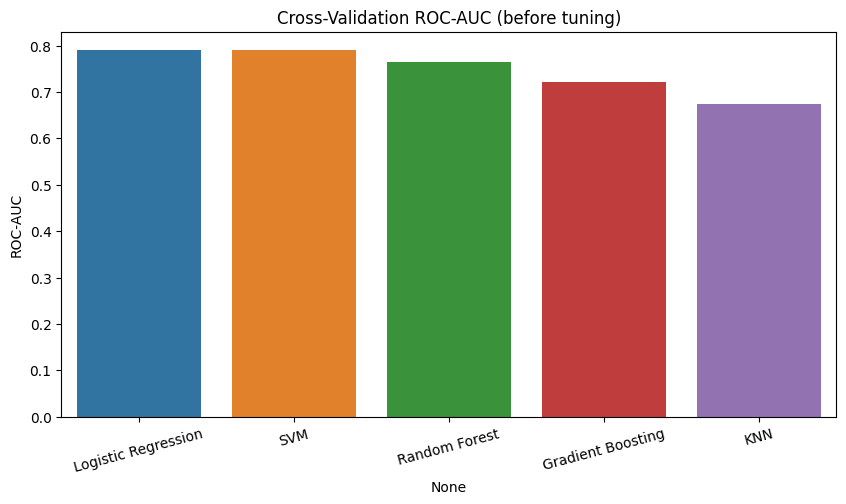

In [36]:
plt.figure(figsize= (10,5))
plt.title('Cross-Validation ROC-AUC (before tuning)')
sns.barplot( x = baseline.index , y= baseline['roc_auc'] , hue= baseline.index)
plt.ylabel('ROC-AUC')
plt.xticks(rotation= 15)
plt.show()

In [37]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01 , 0.1 , 0.5 , 1 , 5 , 10]} ,
    'SVM': {'model__C': [0.1 , 0.5 , 1 , 5] , 'model__gamma': ['scale' , 0.01 , 0.05 , 0.1]} ,
    'Random Forest': {'model__n_estimators': [200] , 'model__max_depth': [3 , 5 , None] , 'model__min_samples_leaf': [1 , 3 , 5]}
}

grid_results = {}
for name, grid in param_grids.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , models[name])])
    grid_results[name] = GridSearchCV(pipe , grid , cv= cv , scoring= 'roc_auc' , n_jobs= -1).fit(X_train , y_train)
    print(name , round(grid_results[name].best_score_ , 3) , grid_results[name].best_params_)

Logistic Regression 0.791 {'model__C': 5}
SVM 0.798 {'model__C': 0.1, 'model__gamma': 0.1}
Random Forest 0.789 {'model__max_depth': 3, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}


In [38]:
best_name = max(grid_results , key= lambda name: grid_results[name].best_score_)
final_model = grid_results[best_name].best_estimator_
best_name

'SVM'

### **Model Evaluation**

In [39]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[: , 1]

print(classification_report(y_test , y_pred , target_names= ['Survived' , 'Died']))

              precision    recall  f1-score   support

    Survived       0.87      0.80      0.84        41
        Died       0.64      0.74      0.68        19

    accuracy                           0.78        60
   macro avg       0.75      0.77      0.76        60
weighted avg       0.79      0.78      0.79        60



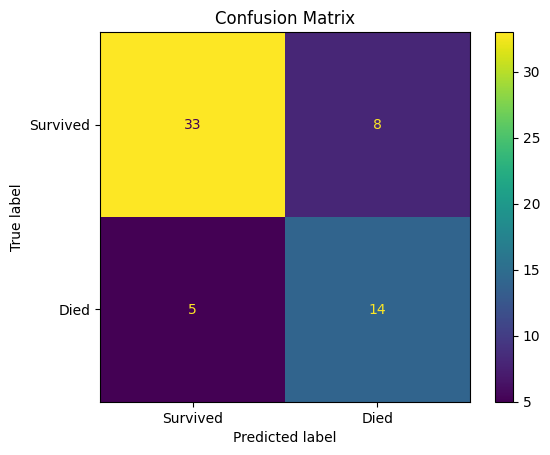

In [40]:
ConfusionMatrixDisplay.from_estimator(final_model , X_test , y_test , display_labels= ['Survived' , 'Died'])
plt.title('Confusion Matrix')
plt.show()

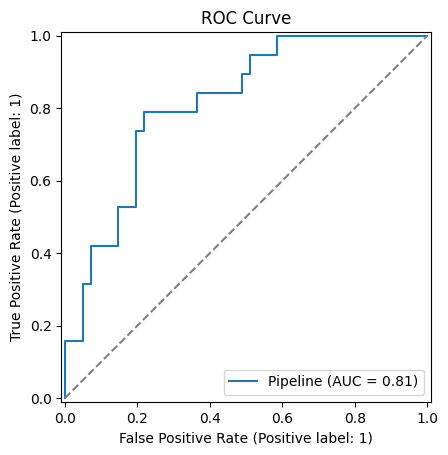

In [41]:
RocCurveDisplay.from_estimator(final_model , X_test , y_test)
plt.plot([0 , 1] , [0 , 1] , ls= '--' , color= 'gray')
plt.title('ROC Curve')
plt.show()

In [42]:
roc_auc_score(y_test , y_prob)

0.8138639281129654

In [43]:
rng = np.random.RandomState(42)
aucs = []
for _ in range(1000):
    idx = rng.randint(0 , len(y_test) , len(y_test))
    if y_test.iloc[idx].nunique() < 2:
        continue
    aucs.append(roc_auc_score(y_test.iloc[idx] , y_prob[idx]))

np.percentile(aucs , [2.5 , 97.5])

array([0.6822705 , 0.90746528])

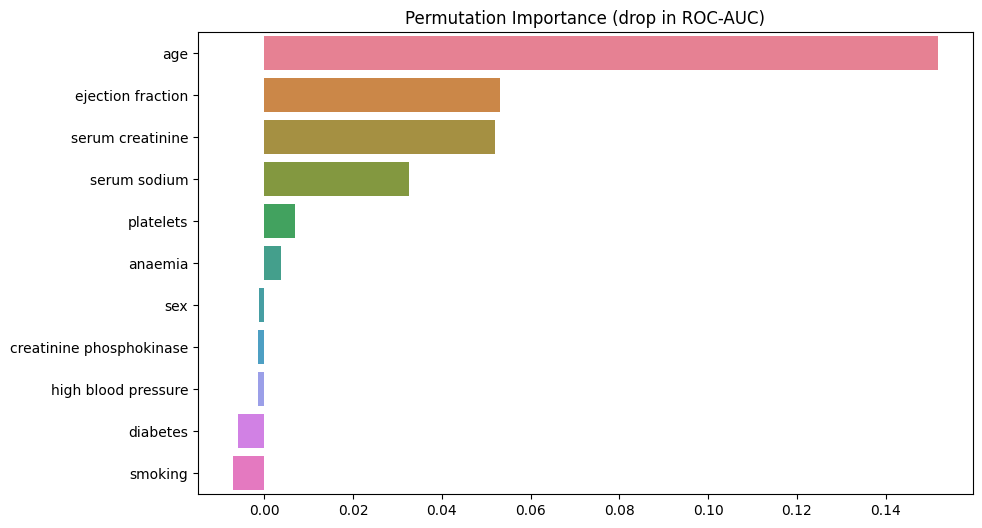

In [44]:
importance = permutation_importance(final_model , X_test , y_test , scoring= 'roc_auc' , n_repeats= 30 , random_state= 42)
importance_df = pd.Series(importance.importances_mean , index= X_test.columns).sort_values(ascending= False)
importance_df.index = importance_df.index.str.replace('_' , ' ')

plt.figure(figsize= (10,6))
plt.title('Permutation Importance (drop in ROC-AUC)')
sns.barplot( x = importance_df.values , y= importance_df.index , hue= importance_df.index)
plt.ylabel('')
plt.show()

In [47]:
X_train_time = df.loc[X_train.index].drop(columns= 'death_event')
model_with_time = Pipeline([('preprocessor' , build_preprocessor(num_cols + ['time'])) , ('model' , clone(final_model.named_steps['model']))])

auc_without_time = cross_val_score(final_model , X_train , y_train , cv= cv , scoring= 'roc_auc').mean()
auc_with_time = cross_val_score(model_with_time , X_train_time , y_train , cv= cv , scoring= 'roc_auc').mean()

auc_without_time , auc_with_time

(np.float64(0.7976657196969695), np.float64(0.8894397095959597))